(2906327, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2906327 entries, 0 to 2906326
Data columns (total 8 columns):
 #   Column          Dtype  
---  ------          -----  
 0   Region          object 
 1   Country         object 
 2   State           object 
 3   City            object 
 4   Month           int64  
 5   Day             int64  
 6   Year            int64  
 7   AvgTemperature  float64
dtypes: float64(1), int64(3), object(4)
memory usage: 177.4+ MB
None

Columns

Index(['Region', 'Country', 'State', 'City', 'Month', 'Day', 'Year',
       'AvgTemperature'],
      dtype='object')

Missing Values

Region                  0
Country                 0
State             1450990
City                    0
Month                   0
Day                     0
Year                    0
AvgTemperature          0
dtype: int64
Total Cities : 321
['Algiers' 'Bujumbura' 'Cotonou' 'Bangui' 'Brazzaville' 'Cairo'
 'Addis Ababa' 'Libreville' 'Banjul' 'Conakry' 'Bissau' 'Abidjan'
 '

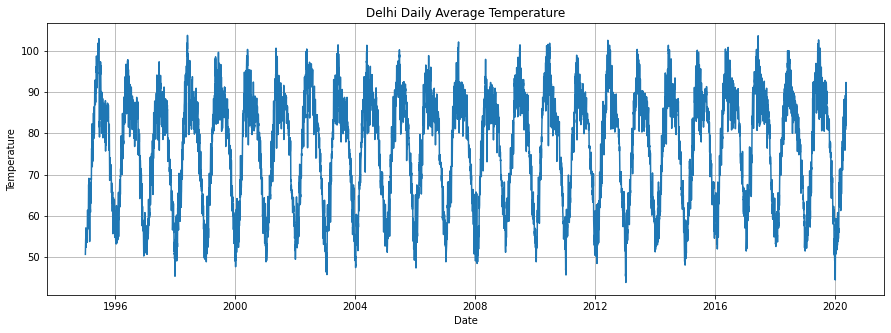

(9205, 1)
Training Samples : (7364, 1)
Testing Samples : (1841, 1)
Training batches : 229
Testing batches : 56
Input Shape : (32, 30, 1)
Output Shape : (32, 1)
Original Sequences
[[1, 2, 3], [4, 5], [6, 7, 8, 9]]

Padded Sequences
[[0 0 1 2 3]
 [0 0 0 4 5]
 [0 6 7 8 9]]
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn (SimpleRNN)      (None, 64)                4224      
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 6337 (24.75 KB)
Trainable params: 6337 (24.75 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/10
229/

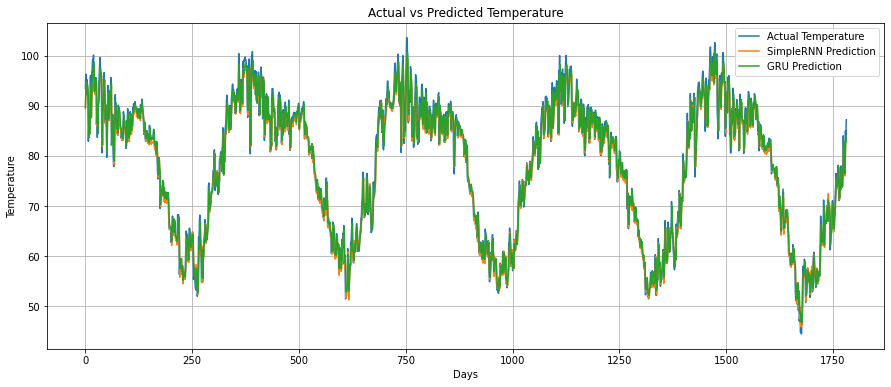

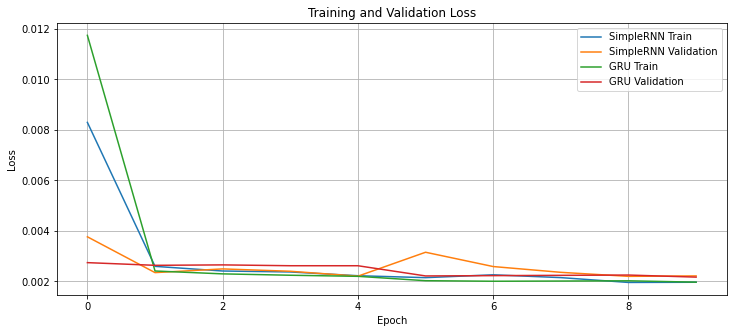

       Model      Loss       MAE
0  SimpleRNN  0.002217  0.036022
1        GRU  0.002169  0.034949


In [4]:
# ============================================================
# TASK 7
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow.keras.utils import timeseries_dataset_from_array
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv(r"C:\dlcity_temperature")

print(df.shape)

df.head()

print(df.info())

print("\nColumns\n")

print(df.columns)

print("\nMissing Values\n")

print(df.isnull().sum())

print("Total Cities :", df["City"].nunique())

print(df["City"].unique())

print(df.columns)

print(df.info())

print(df.isnull().sum())

print(df["City"].nunique())

print(df["City"].unique()[:100])

city_df = df[df["City"]=="Delhi"].copy()

city_df = city_df[city_df["AvgTemperature"]!=-99]

city_df.reset_index(drop=True,inplace=True)

print(city_df.shape)

city_df.head()

city_df = city_df[city_df["AvgTemperature"] != -99]

city_df.reset_index(drop=True, inplace=True)

print(city_df.shape)

city_df["Date"] = pd.to_datetime(

    city_df[["Year","Month","Day"]]

)

city_df = city_df.sort_values("Date")

city_df.reset_index(drop=True,inplace=True)

city_df.head()

temperature = city_df[["AvgTemperature"]]

print(temperature.shape)

temperature.head()

plt.figure(figsize=(15,5))

plt.plot(city_df["Date"],temperature)

plt.title("Delhi Daily Average Temperature")

plt.xlabel("Date")

plt.ylabel("Temperature")

plt.grid(True)

plt.show()

scaler = MinMaxScaler()

scaled_temperature = scaler.fit_transform(temperature)

print(scaled_temperature.shape)

train_size = int(len(scaled_temperature)*0.80)

train = scaled_temperature[:train_size]

test = scaled_temperature[train_size:]

print("Training Samples :",train.shape)

print("Testing Samples :",test.shape)

from tensorflow.keras.utils import timeseries_dataset_from_array

lookback = 30
batch_size = 32

train_dataset = timeseries_dataset_from_array(
    data=train[:-lookback],
    targets=train[lookback:],
    sequence_length=lookback,
    sequence_stride=1,
    shuffle=False,
    batch_size=batch_size
)

test_dataset = timeseries_dataset_from_array(
    data=test[:-lookback],
    targets=test[lookback:],
    sequence_length=lookback,
    sequence_stride=1,
    shuffle=False,
    batch_size=batch_size
)

print("Training batches :", len(train_dataset))
print("Testing batches :", len(test_dataset))

for x, y in train_dataset.take(1):

    print("Input Shape :", x.shape)

    print("Output Shape :", y.shape)

from keras.utils import pad_sequences

sample_sequences = [

    [1,2,3],

    [4,5],

    [6,7,8,9]

]

padded = pad_sequences(

    sample_sequences,

    maxlen=5,

    padding="pre"

)

print("Original Sequences")

print(sample_sequences)

print()

print("Padded Sequences")

print(padded)

simple_rnn = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(lookback,1)),

    tf.keras.layers.SimpleRNN(
        64,
        activation="tanh"
    ),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dense(1)

])

simple_rnn.summary()

Model: "sequential_2"

simple_rnn.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)

callbacks = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True

    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3,

        verbose=1

    )

]

history_rnn = simple_rnn.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=10,

    callbacks=callbacks

)

loss_rnn, mae_rnn = simple_rnn.evaluate(

    test_dataset,

    verbose=0

)

print("SimpleRNN Loss :", loss_rnn)

print("SimpleRNN MAE :", mae_rnn)

stateful_rnn = tf.keras.Sequential([

    tf.keras.layers.Input(batch_shape=(1, lookback, 1)),

    tf.keras.layers.SimpleRNN(

        32,

        stateful=True

    ),

    tf.keras.layers.Dense(1)

])

stateful_rnn.compile(

    optimizer="adam",

    loss="mse"

)

print("Stateful SimpleRNN Created Successfully")

stateful_rnn.summary()

Model: "sequential_3"

gru_model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(lookback,1)),

    tf.keras.layers.GRU(
        64,
        activation="tanh"
    ),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dense(1)

])

gru_model.summary()

Model: "sequential_4"

gru_model.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)

history_gru = gru_model.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=10,

    callbacks=callbacks

)

loss_gru, mae_gru = gru_model.evaluate(

    test_dataset,

    verbose=0

)

print("GRU Loss :", loss_gru)

print("GRU MAE :", mae_gru)

pred_rnn = simple_rnn.predict(test_dataset)

pred_gru = gru_model.predict(test_dataset)

actual = []

for _, y in test_dataset:

    actual.extend(y.numpy())

actual = np.array(actual)

pred_rnn = scaler.inverse_transform(pred_rnn)

pred_gru = scaler.inverse_transform(pred_gru)

actual = scaler.inverse_transform(actual.reshape(-1,1))

plt.figure(figsize=(15,6))

plt.plot(actual,label="Actual Temperature")

plt.plot(pred_rnn,label="SimpleRNN Prediction")

plt.plot(pred_gru,label="GRU Prediction")

plt.title("Actual vs Predicted Temperature")

plt.xlabel("Days")

plt.ylabel("Temperature")

plt.legend()

plt.grid(True)

plt.show()

plt.figure(figsize=(12,5))

plt.plot(history_rnn.history["loss"],label="SimpleRNN Train")

plt.plot(history_rnn.history["val_loss"],label="SimpleRNN Validation")

plt.plot(history_gru.history["loss"],label="GRU Train")

plt.plot(history_gru.history["val_loss"],label="GRU Validation")

plt.title("Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

comparison = pd.DataFrame({

    "Model":["SimpleRNN","GRU"],

    "Loss":[loss_rnn,loss_gru],

    "MAE":[mae_rnn,mae_gru]

})

print(comparison)
